# 02 — Pré-processamento para a MLP e a CNN (CirCor DigiScope)

Transforma as gravações em entradas de tamanho fixo para os dois modelos, com as decisões justificadas em `01_eda.ipynb`.
O código está em `src/features.py` (configuração e extração), `src/prepare_data.py` (corre tudo e grava em `data/processed/`)
e `src/datasets.py` (carregar, normalizar por fold e agregar por paciente). A organização segue a do projeto UrbanSound8K
(`example/.../preprocess/`).

1. Decisões de pré-processamento (UrbanSound8K vs CirCor)
2. Gerar os dados processados
3. Do sinal às entradas dos modelos
4. As features da MLP separam as classes?
5. Split, desequilíbrio e como usar os dados nos modelos

In [1]:
import sys; sys.path.insert(0, '..')
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
import librosa, librosa.display
import warnings; warnings.filterwarnings('ignore', category=FutureWarning)

from src.data import load_split, WAV_DIR, CLASSES
from src import features as F

pd.set_option('display.width', 140)
sns.set_theme(style='whitegrid', context='notebook')
PALETTE = {'Present': '#d62728', 'Unknown': '#7f7f7f', 'Absent': '#1f77b4'}
FIG_DIR = Path('../results/preprocessing'); FIG_DIR.mkdir(parents=True, exist_ok=True)
save = lambda name: plt.savefig(FIG_DIR / f'{name}.png', dpi=150, bbox_inches='tight')

## 1. Decisões de pré-processamento
Seguimos a mesma estrutura do projeto UrbanSound8K (`preprocess/config.py`, `features_mlp.py`, `features_cnn.py`,
`prepare_data.py`), adaptada ao PCG. O código está em `src/features.py`, `src/prepare_data.py` e `src/datasets.py`.

| passo | UrbanSound8K (example) | CirCor (este projeto) | porquê (secção) |
|---|---|---|---|
| sample rate | reamostrar para 22 050 Hz | **4 kHz nativo** | tudo já a 4 kHz, energia < 1.5 kHz (01 §4, §7) |
| filtragem | — | **passa-banda 25–1000 Hz** (Butterworth 4ª ordem, fase zero) | remove deriva e ruído agudo (01 §7) |
| amplitude | — | **z-score por gravação** | volumes muito diferentes entre gravações/estetoscópios |
| duração | crop/pad a 4 s | **janelas de 4 s, passo 2 s**; última janela parcial com pad se ≥ 2 s | gravações de 5–65 s, ≥ 3 ciclos por janela (~7 na mediana) (01 §4, §6) |
| rótulo | classe do clip | **`rec_label`** por gravação (dos `Murmur locations`) | o sopro pode não estar em todos os focos (01 §5) |
| MLP | 40 MFCC × (mean, std, Δ, ΔΔ) = 160 | **99 features por janela**: 20 MFCC (mean, std, std Δ, std ΔΔ) + 6 descritores espectrais (mean, std) + energia em 5 bandas + periodicidade do envelope | sopro = energia de banda larga na sístole (01 §6), *Unknown* = pouco periódico (01 §8) |
| CNN | mel 128 × 174, min-max [0,1] por amostra | **log-mel 40 × 401** (n_fft 256 = 64 ms, hop 40 = 10 ms, 20–1000 Hz), em dB sem min-max | resolução temporal para S1/sístole/S2 (01 §3); o nível absoluto ajuda a detetar ruído |
| normalização | por fold, só treino | **por fold, só treino**: z-score por feature (MLP) e por banda mel (CNN) | sem *data leakage* |
| previsão final | 1 por clip | janelas → gravação → **paciente** | 1 previsão por paciente (enunciado) |

Os dados guardados não têm nenhuma normalização ajustada aos dados, por isso podem ser gerados uma vez para todos os folds.

## 2. Gerar os dados processados
Equivalente a `python -m src.prepare_data`. Só corre se `data/processed/` ainda não existir (ou com `FORCE = True`).

In [2]:
from src.prepare_data import prepare_data, OUT_DIR
FORCE = False   # True para regenerar (≈ 1–3 min com todos os cores)
if FORCE or not (OUT_DIR / 'X_mlp.npy').exists():
    prepare_data()
else:
    print('a usar ficheiros já existentes em', OUT_DIR.resolve())

a usar ficheiros já existentes em C:\Users\rafa\Documents\FCUP\AC 2\FCUP-DL-ML2\data\processed


X_mlp : (31409, 99) float32
mel   : (40, 7235810) float16 579 MB  -> janelas CNN de (40, 401)
janelas: 31409 | gravações: 3163 | pacientes: 942


,recording,patient_id,location,start_s,mel_start,murmur,rec_label,fold
0,13918_AV,13918,AV,0.0,0,Present,Absent,4
1,13918_AV,13918,AV,2.0,200,Present,Absent,4
2,13918_AV,13918,AV,4.0,400,Present,Absent,4
3,13918_AV,13918,AV,6.0,600,Present,Absent,4
4,13918_MV,13918,MV,0.0,1029,Present,Absent,4


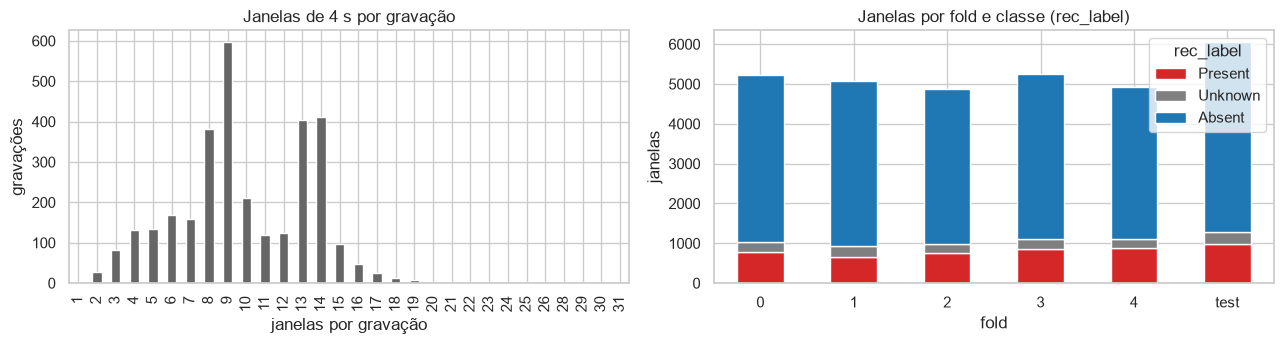

In [3]:
from src.datasets import load_processed, fold_masks, mlp_arrays, mel_band_stats, cnn_arrays, class_weights, aggregate_to_patient
d = load_processed()
print('X_mlp :', d.X_mlp.shape, d.X_mlp.dtype)
print('mel   :', d.mel.shape, d.mel.dtype, f'{d.mel.nbytes / 1e6:.0f} MB  -> janelas CNN de', (d.mel.shape[0], d.config['frames_per_window']))
print('janelas:', len(d.windows), '| gravações:', len(d.recordings), '| pacientes:', d.windows.patient_id.nunique())
display(d.windows.head())

fig, ax = plt.subplots(1, 2, figsize=(13, 3.6))
d.recordings.n_windows.value_counts().sort_index().plot.bar(ax=ax[0], color='0.4')
ax[0].set(xlabel='janelas por gravação', ylabel='gravações', title='Janelas de 4 s por gravação')
pd.crosstab(d.windows.fold.replace({-1: 'test'}), d.windows.rec_label)[CLASSES].plot.bar(
    stacked=True, ax=ax[1], color=[PALETTE[c] for c in CLASSES], rot=0)
ax[1].set(xlabel='fold', ylabel='janelas', title='Janelas por fold e classe (rec_label)')
plt.tight_layout(); save('windows_per_fold'); plt.show()

## 3. Do sinal às entradas dos modelos (uma janela)

c:\Users\rafa\AppData\Local\Programs\Python\Python314\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


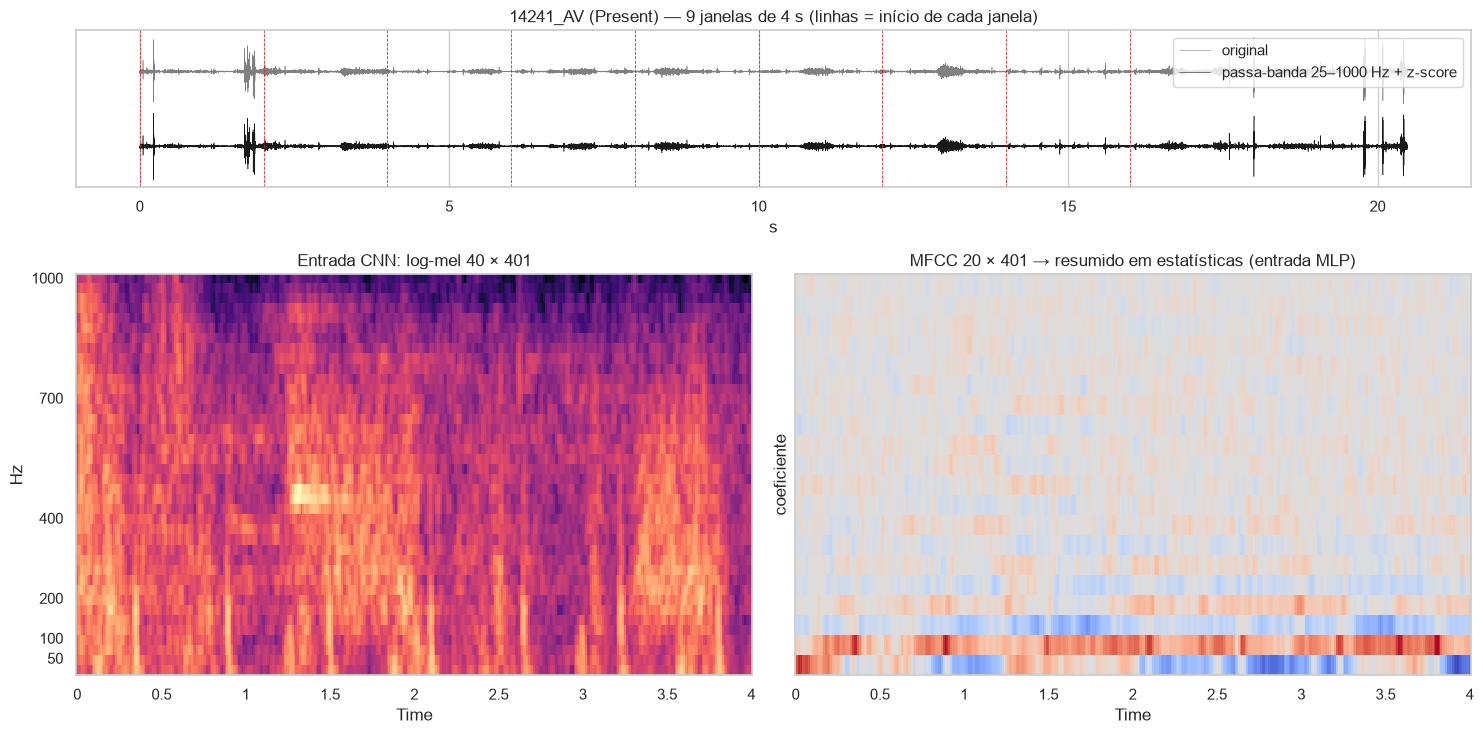

In [4]:
r = d.recordings[(d.recordings.rec_label == 'Present') & (d.recordings.n_windows >= 5)].iloc[0]
path = str(WAV_DIR / f'{r.recording}.wav')
raw, sr = librosa.load(path, sr=None)
y = F.load_audio(path)
wins, starts = F.split_windows(y)
w = wins[1]
mel_w = F.logmel(w)
mfcc_w = librosa.feature.mfcc(y=w, sr=sr, n_mfcc=F.MFCC.n_mfcc, n_fft=F.MFCC.n_fft, hop_length=F.MFCC.hop_length,
                              n_mels=F.MFCC.n_mels, fmin=F.MFCC.fmin, fmax=F.MFCC.fmax)

fig = plt.figure(figsize=(15, 7.5)); gs = fig.add_gridspec(3, 2)
a = fig.add_subplot(gs[0, :]); t = np.arange(len(raw)) / sr
a.plot(t, raw / np.abs(raw).max() + 2.2, lw=.4, color='0.5', label='original')
a.plot(t, y / np.abs(y).max(), lw=.4, color='k', label='passa-banda 25–1000 Hz + z-score')
for s in starts: a.axvline(s, color='#d62728', lw=.6, ls='--')
a.set(title=f'{r.recording} ({r.rec_label}) — {len(starts)} janelas de 4 s (linhas = início de cada janela)', xlabel='s', yticks=[]); a.legend(loc='upper right')
a = fig.add_subplot(gs[1:, 0])
librosa.display.specshow(mel_w, sr=sr, hop_length=F.MEL.hop_length, x_axis='time', y_axis='mel',
                         fmin=F.MEL.fmin, fmax=F.MEL.fmax, ax=a, cmap='magma')
a.set(title=f'Entrada CNN: log-mel {mel_w.shape[0]} × {mel_w.shape[1]}', yticks=[50, 100, 200, 400, 700, 1000])
a = fig.add_subplot(gs[1:, 1])
librosa.display.specshow(mfcc_w, sr=sr, hop_length=F.MFCC.hop_length, x_axis='time', ax=a, cmap='coolwarm')
a.set(title=f'MFCC {mfcc_w.shape[0]} × {mfcc_w.shape[1]} → resumido em estatísticas (entrada MLP)', ylabel='coeficiente')
plt.tight_layout(); save('features_example'); plt.show()

## 4. As features da MLP separam as classes?
Antes de treinar, verificamos se as features escolhidas têm sinal: distribuição de algumas features por classe e uma PCA.
Usamos só os folds de treino, para não olhar para o teste.

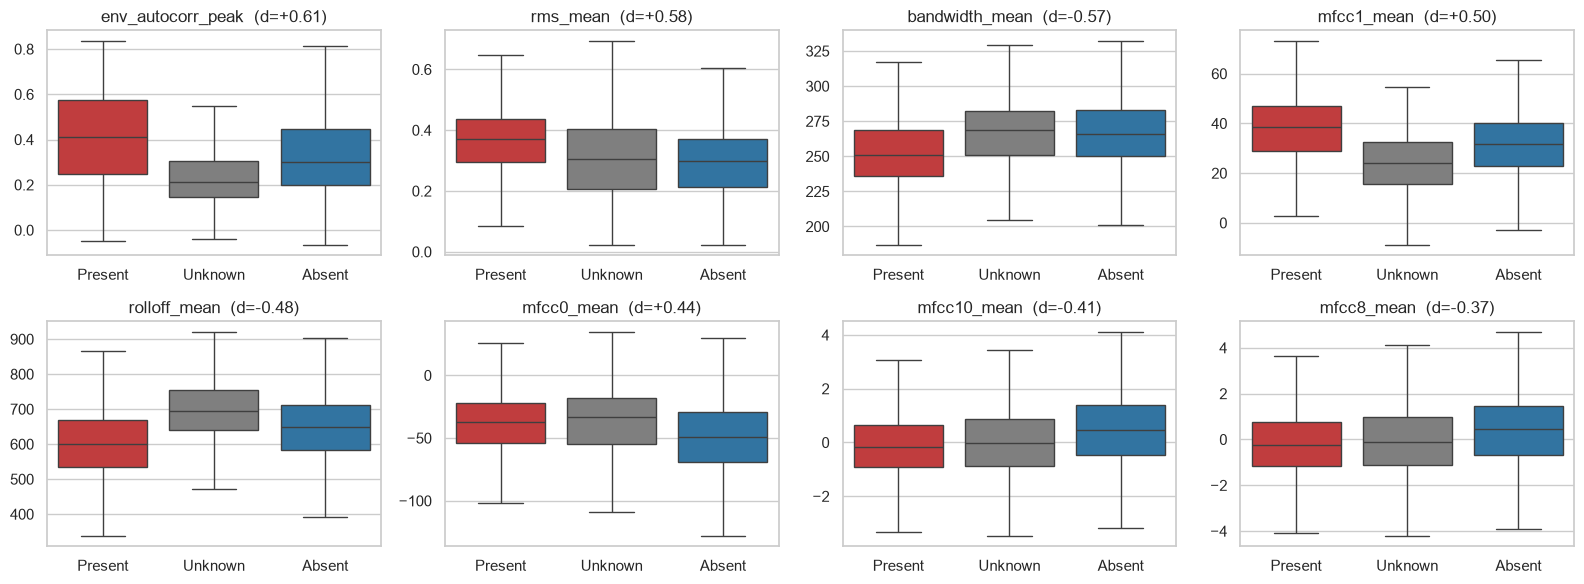

In [5]:
names = d.config['mlp_features']
dev = d.windows.fold >= 0
Xf = pd.DataFrame(d.X_mlp[dev], columns=names); Xf['rec_label'] = d.windows.loc[dev, 'rec_label'].values

# features mais discriminativas Present vs Absent (diferença de medianas / desvio padrão)
z = (Xf[Xf.rec_label == 'Present'][names].median() - Xf[Xf.rec_label == 'Absent'][names].median()) / Xf[names].std()
top = z.abs().sort_values(ascending=False).index[:8]
fig, axes = plt.subplots(2, 4, figsize=(16, 6))
for ax, col in zip(axes.flat, top):
    sns.boxplot(x=Xf.rec_label, y=Xf[col], order=CLASSES, palette=PALETTE, ax=ax, showfliers=False)
    ax.set(title=f'{col}  (d={z[col]:+.2f})', xlabel='', ylabel='')
plt.tight_layout(); save('mlp_top_features'); plt.show()

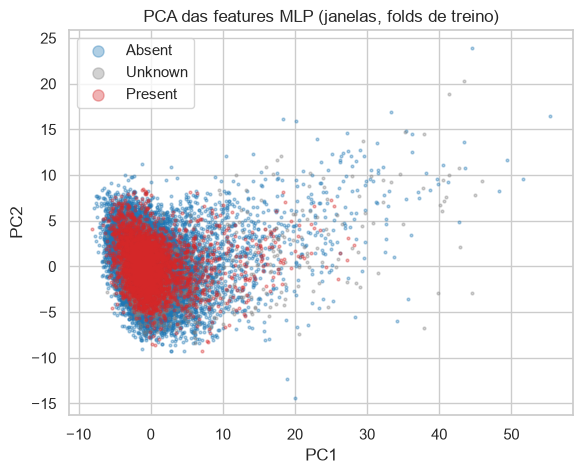

In [6]:
from sklearn.decomposition import PCA
from src.features import Standardizer
Z = PCA(2, random_state=0).fit_transform(Standardizer().fit_transform(d.X_mlp[dev]))
fig, ax = plt.subplots(figsize=(6.5, 5))
for c in ['Absent', 'Unknown', 'Present']:
    m = Xf.rec_label.values == c
    ax.scatter(Z[m, 0], Z[m, 1], s=4, alpha=.35, color=PALETTE[c], label=c)
ax.set(title='PCA das features MLP (janelas, folds de treino)', xlabel='PC1', ylabel='PC2'); ax.legend(markerscale=4)
save('mlp_pca'); plt.show()

**Leitura.** As features espectrais e as estatísticas dos MFCC mudam de forma consistente entre *Present* e *Absent*,
mas as classes sobrepõem-se muito na PCA. Nenhuma feature sozinha resolve o problema, por isso faz sentido um modelo não linear.
A sobreposição ao nível da janela também é esperada: mesmo num foco com sopro, uma janela ruidosa pode não o mostrar.
Agregar várias janelas e focos por paciente compensa isto.

## 5. Split, desequilíbrio e como usar os dados nos modelos

In [7]:
split = load_split()
display(pd.crosstab(split.fold.replace({-1: 'test'}), split.murmur, margins=True)[CLASSES + ['All']])
assert split.groupby('group').fold.nunique().max() == 1   # criança das 2 campanhas no mesmo fold
assert d.windows.groupby('patient_id').fold.nunique().max() == 1
print('split por paciente/grupo: OK')

tr, va, te = fold_masks(d.windows, val_fold=0)
Xtr, ytr, Xva, yva, scaler = mlp_arrays(d, tr, va)
print('\nexemplo fold de validação 0 -> MLP treino', Xtr.shape, '| validação', Xva.shape,
      '| média/desvio treino após normalização:', Xtr.mean().round(3), Xtr.std().round(3))
print('pesos de classe (Present, Unknown, Absent):', class_weights(ytr).round(2))
band = mel_band_stats(d, tr)
Xc, yc = cnn_arrays(d, va, band)
print('CNN validação:', Xc.shape, '(n, canal, mel, frames)')

murmur,Present,Unknown,Absent,All
fold,,,,
0,29,11,111,151
1,28,11,112,151
2,28,11,111,150
3,29,11,111,151
4,29,10,111,150
test,36,14,139,189
All,179,68,695,942


split por paciente/grupo: OK

exemplo fold de validação 0 -> MLP treino (20135, 99) | validação (5232, 99) | média/desvio treino após normalização: -0.0 1.0
pesos de classe (Present, Unknown, Absent): [0.68 2.18 0.13]
CNN validação: (5232, 1, 40, 401) (n, canal, mel, frames)


### Resumo das decisões para os modelos

**Entradas (geradas por `python -m src.prepare_data`, em `data/processed/`)**
- MLP: `X_mlp.npy`, um vetor de 99 features por janela de 4 s. Normalização z-score com a média e o desvio do treino (`mlp_arrays`).
- CNN 2D: log-mel 40 × 401 por janela, cortada de `mel.npy` em tempo real (`CNNWindows`, ou `cnn_arrays` para tudo em memória),
  normalizada por banda mel com estatísticas do treino. Com `random_crop=True` cada época vê cortes diferentes (*time-shift augmentation*).
  Também se podem acrescentar SpecAugment (máscaras de tempo/frequência) e ruído gaussiano, como no UrbanSound8K.

**Protocolo** (`splits/split.csv`, por paciente e estratificado)
- 20 % dos pacientes ficam no teste (fold −1), que **só** se usa para os números finais.
- 5 folds de validação cruzada nos restantes 80 %, para escolher arquitetura, early stopping, limiares e agregação.

**Desequilíbrio**
- Cross-entropy com pesos de classe (`class_weights`), eventualmente combinada com os pesos da métrica (5/3/1).
- Limiar de decisão afinado na validação para maximizar a *weighted accuracy*.

**Uma previsão por paciente** (`aggregate_to_patient`)
- As probabilidades das janelas fazem-se a média por gravação.
- Para o paciente, a opção `max_present` usa a gravação com maior P(Present): basta um foco com sopro (01 §5).
  A alternativa `mean` faz a média de todas as janelas. A escolha entre as duas faz-se na validação.
- Regra a experimentar (como no Challenge): *Present* se algum foco passar o limiar; senão *Unknown* se P(Unknown) for alta; senão *Absent*.